# 08. Original crime: endpoint and pre-2014 robustness

This notebook repeats M1–M7 for current-year (`annual`) and previous-year (`lagyear`) original crime on two common sale windows: **2012–2014** and **2012–2013**. The first avoids 2010 previous-year and 2015 current-year crime exposures. The second also avoids the all-zero 2014–2015 supplied violent-crime counts for current-year exposure. Each exposure pair uses exactly the same transactions within its window.

The full 2011–2015 baseline comes from notebook 01. Changing sale years also changes the sample, so differences across windows are descriptive robustness checks rather than tests of a single coefficient's change. This notebook writes only to its own output folder and does not update the dashboard.

In [1]:
from pathlib import Path
try:
    from google.colab import drive
except ImportError:
    ROOT = Path.cwd()
else:
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/HE3027 Project')
DATA_DIR = ROOT / 'data'
DATA_DIR.mkdir(parents=True, exist_ok=True)

OUT = DATA_DIR / '08_crime_original_robustness_outputs'
OUT.mkdir(exist_ok=True)
MERGED = DATA_DIR / 'crime_housing_merged.csv.gz'
if not MERGED.is_file():
    raise FileNotFoundError('Run crime_housing_project_analysis.ipynb first.')
RUN_STRICT = False
SALE_YEARS = (2012, 2014)
EXPOSURES = ['annual', 'lagyear']
MAIN = ['allcrime', 'violent_crime', 'propertycrime']
AVAILABILITY = 'original_pair_available'


In [2]:
import hashlib
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
CRIMES = ['allcrime', 'violent_crime', 'propertycrime']
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 4)

def table(data, filename):
    """Save the complete table and display a compact preview."""
    data.to_csv(OUT / (filename + '.csv'))
    display(data.head(20) if len(data) > 20 else data)
    if len(data) > 20:
        print(f'Showing 20 of {len(data)} rows; the complete table is saved as {filename}.csv.')

VARIABLE_LABELS = {
    'detached_dum': 'Detached (relative to flat)',
    'semi_d_dum': 'Semi-detached (relative to flat)',
    'terrace_dum': 'Terraced (relative to flat)',
    'freehold': 'Freehold',
    'newbuild': 'New build',
    'tube_distnear_km': 'Distance to tube station (km)',
    'bus_distnear_km': 'Distance to bus stop (km)',
    'thamesriv_dist_km': 'Distance to Thames (km)',
    'Nearest_Park_dist_km': 'Distance to park (km)',
    'dist_to_cbd': 'Distance to CBD (km)',
    'Bus_stopscount_200m': 'Bus stops within 200m',
    'heritage_count_200m': 'Heritage buildings within 200m',
    'percent_noedu': 'Residents without qualifications',
    'percent_minorities': 'Minority residents',
    'lone_hh': 'Lone-parent households',
    'lnpay': 'Log borough annual pay',
    'jobdensity': 'Borough job density',
    'hoursworked': 'Borough weekly hours worked',
    'unemployment': 'Borough unemployment',
}

def coefficient_inference(coefficients, results):
    """Compute inference for every coefficient from its saved clustered SE."""
    keys = [name for name in ['panel', 'model', 'crime', 'measure', 'timing']
            if name in coefficients and name in results]
    metadata = results[keys + ['clusters']]
    enriched = coefficients.drop(columns=['clusters', 't', 'p', 'ci_low', 'ci_high'], errors='ignore')
    enriched = enriched.merge(metadata, on=keys, how='left', validate='many_to_one')
    if enriched.clusters.isna().any():
        raise ValueError('Coefficient rows could not be matched to regression metadata.')
    degrees_freedom = enriched.clusters - 1
    enriched['t'] = enriched.beta / enriched.se
    enriched['p'] = 2 * stats.t.sf(np.abs(enriched.t), degrees_freedom)
    critical = stats.t.ppf(0.975, degrees_freedom)
    enriched['ci_low'] = enriched.beta - critical * enriched.se
    enriched['ci_high'] = enriched.beta + critical * enriched.se
    return enriched

def show_models(results, filename, coefficient_filename):
    """Show one expandable table per model with crime AND control coefficients."""
    from html import escape
    from IPython.display import HTML

    results.to_csv(OUT / (filename + '.csv'), index=False)
    coefficients = coefficient_inference(pd.read_csv(OUT / coefficient_filename), results)
    coefficients.to_csv(OUT / coefficient_filename, index=False)
    cards = []

    def number(value):
        if pd.isna(value):
            return '—'
        if value != 0 and abs(value) < 0.0001:
            return f'{value:.2e}'
        return f'{value:.4f}'

    for _, regression in results.iterrows():
        selected = coefficients.model.eq(regression['model'])
        for key in ['panel', 'crime', 'measure', 'timing']:
            if key in coefficients and key in results:
                selected &= coefficients[key].eq(regression[key])
        rows = coefficients.loc[selected].copy()
        title = regression['model'] + ' · ' + str(regression.get('crime', regression.get('measure', '')))
        if 'timing' in results:
            title += ' · ' + regression['timing']
        rendered = []
        for _, row in rows.iterrows():
            label = VARIABLE_LABELS.get(row.variable, row.variable)
            if row.variable.startswith('log1p_'):
                label = 'Crime: log(1 + ' + row.variable[6:].replace('_', ' ') + ')'
            rendered.append({
                'Variable': label,
                'Coefficient': number(row.beta),
                'Clustered SE': number(row.se),
                't statistic': f'{row.t:.2f}',
                '95% CI': number(row.ci_low) + ' to ' + number(row.ci_high),
                'p-value': '<0.001' if row.p < 0.001 else f'{row.p:.3f}',
            })
        effects = regression.get('fixed_effects', '')
        effects = 'None' if pd.isna(effects) or not effects else str(effects)
        r2_label = 'Within R²' if regression.r2_type == 'within' else 'R²'
        subtitle = (f'N = {int(regression.N):,} | LSOA clusters = {int(regression.clusters):,}'
                    f' | {r2_label} = {regression.r2:.4f}')
        body = pd.DataFrame(rendered).to_html(index=False, border=0, escape=True)
        omitted = regression.get('absorbed_or_collinear', '')
        note = '' if pd.isna(omitted) or not omitted else '<p>Absorbed/collinear: ' + escape(str(omitted)) + '</p>'
        cards.append('<details class="reg-card"><summary>' + escape(title) + '</summary>'
                     '<p>' + escape(subtitle) + '</p><p>Fixed effects: ' + escape(effects) + '</p>'
                     + body + note + '</details>')
    style = '<style>.reg-card{margin:10px 0;padding:12px;border:1px solid #bbb;border-radius:6px;overflow-x:auto}.reg-card summary{cursor:pointer;font-weight:600}.reg-card table{border-collapse:collapse;width:100%;max-width:950px}.reg-card th,.reg-card td{padding:7px 10px;border-bottom:1px solid #ddd;text-align:right;white-space:nowrap}.reg-card th:first-child,.reg-card td:first-child{text-align:left}.reg-card p{font-size:13px}</style>'
    display(HTML(style + '<p>Expand a regression to view all estimated coefficients. Standard errors are clustered by LSOA.</p>' + ''.join(cards)))
    return coefficients


In [3]:
import json
df = pd.read_csv(MERGED, low_memory=False)
manifest = json.loads((DATA_DIR / 'crime_housing_manifest.json').read_text(encoding='utf-8'))
assert len(df) == manifest['rows'] and df.transaction_id.is_unique
for flag in ['analysis_geography_ok','original_pair_available','mps_exposures_available','mps_geography_ok']:
    assert pd.api.types.is_bool_dtype(df[flag]), 'Invalid saved coverage flag: ' + flag


In [4]:
LOCATION_MODE = 'continuous'
RIVER_THRESHOLD_METRES = None

data = df.copy()
data['lnprice'] = np.log(data.price.where(data.price.gt(0)))
data['newbuild'] = data.age.eq('Y').astype(float)
data['grossannualpay_k'] = data.grossannualpay / 1000
data['Nearest_Park_dist_km'] = data['Nearest_Park_dist'] / 1000
PROPERTY = ['detached_dum','semi_d_dum','terrace_dum','freehold','newbuild']
ECONOMIC = ['grossannualpay_k','jobdensity','hoursworked','unemployment']
if LOCATION_MODE == 'continuous':
    LOCATION = []
    for name in ['tube_distnear','bus_distnear','thamesriv_dist']:
        data[name+'_km'] = data[name]/1000
        LOCATION.append(name+'_km')
    LOCATION += ['dist_to_cbd','Nearest_Park_dist_km']
elif LOCATION_MODE == 'indicators':
    if RIVER_THRESHOLD_METRES is None or RIVER_THRESHOLD_METRES <= 0:
        raise ValueError('Specify a positive river proximity threshold in metres.')
    thresholds = {'tube_distnear':200, 'bus_distnear':200, 'thamesriv_dist':RIVER_THRESHOLD_METRES}
    LOCATION = ['tube_near','bus_near','river_near']
    for name, target in zip(thresholds,LOCATION):
        data[target] = data[name].le(thresholds[name]).astype(float).where(data[name].notna())
else:
    raise ValueError('LOCATION_MODE must be continuous or indicators.')
VARIABLE_LABELS.update({'grossannualpay_k':'Borough annual pay (GBP 1,000)',
                        'tube_near':'Tube station within 200m', 'bus_near':'Bus stop within 200m',
                        'river_near':'River within specified threshold'})


In [5]:
CRIME_COLUMNS = []
for category in MAIN:
    for exposure in ['annual', 'lagyear']:
        source = category + '_' + exposure
        if data[source].dropna().lt(0).any():
            raise ValueError('Negative crime counts: ' + source)
        name = 'log1p_' + source
        data[name] = np.log1p(data[source])
        CRIME_COLUMNS.append(name)
EXPOSURE = EXPOSURES[0]


## 1. One consistent model sequence

| Model | Controls | Fixed effects |
|---|---|---|
| M1 | Property only; no crime | None |
| M2 | Property + crime | None |
| M3 | Property + crime + location + economic | None |
| M4 | Same as M3 | Local authority + year |
| M5 | Same as M3 | MSOA + year |
| M6 | Same as M3 | MSOA + year-quarter |
| M7 | Same as M3 | LSOA + year-quarter |

This final numbering differs from the earlier reconciled notebook: M3 now isolates adding observable controls. Crime timing is constant through M2-M7 within each panel; no model is chosen for its sign.

Let $z_i=\ln(1+C_i)$, $H_i$ be property controls and $W_i$ be location/economic controls. Model-specific coefficients are re-estimated at every stage:

$$\mathrm{M1}:\quad \ln P_i=\alpha+\gamma'H_i+\epsilon_i$$
$$\mathrm{M2}:\quad \ln P_i=\alpha+\beta z_i+\gamma'H_i+\epsilon_i$$
$$\mathrm{M3}:\quad \ln P_i=\alpha+\beta z_i+\gamma'H_i+\theta'W_i+\epsilon_i$$
$$\mathrm{M4}:\quad \ln P_i=\alpha+\beta z_i+\gamma'H_i+\theta'W_i+\mu_b+\tau_y+\epsilon_i$$
$$\mathrm{M5}:\quad \ln P_i=\alpha+\beta z_i+\gamma'H_i+\theta'W_i+\mu_m+\tau_y+\epsilon_i$$
$$\mathrm{M6}:\quad \ln P_i=\alpha+\beta z_i+\gamma'H_i+\theta'W_i+\mu_m+\lambda_q+\epsilon_i$$
$$\mathrm{M7}:\quad \ln P_i=\alpha+\beta z_i+\gamma'H_i+\theta'W_i+\nu_l+\lambda_q+\epsilon_i$$

For current-year crime, $C_i=C_{l,y}$. For previous-year crime, $C_i=C_{l,y-1}$. Prior12 uses the twelve completed months preceding the sale month. There are no borough-year effects. Year-quarter replaces year effects, and finer area effects replace broader area effects.


In [6]:
def model_specs(include_jobdensity=False):
    economic = [c for c in ECONOMIC if include_jobdensity or c != 'jobdensity']
    full = PROPERTY + LOCATION + economic
    return [
        ('M1', None, PROPERTY, []),
        ('M2', EXPOSURE, PROPERTY, []),
        ('M3', EXPOSURE, full, []),
        ('M4', EXPOSURE, full, ['oslaua','year']),
        ('M5', EXPOSURE, full, ['msoa11','year']),
        ('M6', EXPOSURE, full, ['msoa11','yearquarter']),
        ('M7', EXPOSURE, full, ['lsoacode','yearquarter']),
    ]


In [7]:
def make_sample(include_jobdensity):
    full = model_specs(include_jobdensity)[-1][2]
    required = ['lnprice','lsoacode','msoa11','oslaua','year','yearquarter'] + full + CRIME_COLUMNS
    valid = data[required].replace('', np.nan).notna().all(axis=1)
    valid &= np.isfinite(data[required].select_dtypes(include='number')).all(axis=1)
    valid &= data.analysis_geography_ok & data[AVAILABILITY]
    valid &= data.year.between(*SALE_YEARS)
    return data.loc[valid].copy()
sample = make_sample(False)
print('Primary sample:',len(sample),'sales;',sample.lsoacode.nunique(),'LSOA clusters')
table(sample.groupby('year').size().to_frame('sales'), 'sample_by_year')

assert set(sample.year.unique()) == set(range(SALE_YEARS[0], SALE_YEARS[1] + 1))


Primary sample: 316091 sales; 4819 LSOA clusters


,sales
year,
2012,91674
2013,107274
2014,117143


## 2. Estimation helpers

The following cells define absorption and LSOA-clustered inference. Expandable coefficient tables include every identified control. Absorbed/collinear controls are listed. Fixed-effects R-squared is within R-squared; compare it with the same definition only. The estimator uses a cluster-count correction, without a further absorbed-effect degrees-of-freedom correction. It does not report intercepts or individual fixed effects.


In [8]:
from linearmodels.iv import AbsorbingLS
def absorb(matrix, groups, tol=1e-10, max_iter=2000):
    z = np.asarray(matrix, dtype=float).copy()
    codes = [pd.factorize(g, sort=False)[0] for g in groups]
    if any(((g < 0).any() for g in codes)):
        raise ValueError('Missing fixed-effect ID')
    for iteration in range(max_iter):
        before = z.copy()
        for g in codes:
            counts = np.bincount(g)
            sums = np.column_stack([np.bincount(g, weights=z[:, j], minlength=len(counts)) for j in range(z.shape[1])])
            z -= (sums / counts[:, None])[g]
        if np.max(np.abs(z - before)) < tol:
            return (z, iteration + 1)
    raise RuntimeError('Fixed-effect absorption did not converge')
def fit_absorbed(data, crime, controls, fixed_effects, cluster='lsoacode'):
    """Estimate OLS with high-dimensional fixed effects using linearmodels."""
    names = ([crime] if crime is not None else []) + controls
    x = data[names].astype(float).copy()
    y = data.lnprice.astype(float).copy()
    scale = x.std(axis=0).to_numpy().copy()
    scale[scale < 1e-14] = 1
    x_scaled = x / scale
    if fixed_effects:
        absorbed = pd.DataFrame(
            {c: pd.Categorical(data[c]) for c in fixed_effects}, index=data.index
        )
    else:
        absorbed = None
        y = y - y.mean()
        x_scaled = x_scaled - x_scaled.mean(axis=0)
    fit = AbsorbingLS(
        y, x_scaled, absorb=absorbed, drop_absorbed=True
    ).fit(cov_type='clustered', clusters=data[cluster], debiased=True)
    group = pd.factorize(data[cluster], sort=False)[0]
    G = int(group.max() + 1)
    if G < 2:
        raise ValueError('Need multiple inference clusters')
    identified = list(fit.params.index)
    if crime is not None and crime not in identified:
        raise ValueError('Crime has no identifying variation in this specification')
    estimates = fit.params.to_numpy() / scale[[names.index(c) for c in identified]]
    se = fit.std_errors.to_numpy() / scale[[names.index(c) for c in identified]]
    critical = stats.t.ppf(0.975, G - 1)
    j = identified.index(crime) if crime is not None else 0
    result = {
        'N': len(data), 'clusters': G,
        'beta': estimates[j] if crime is not None else np.nan,
        'se': se[j] if crime is not None else np.nan,
        'p': 2 * stats.t.sf(abs(estimates[j] / se[j]), G - 1) if crime is not None else np.nan,
        'ci_low': estimates[j] - critical * se[j] if crime is not None else np.nan,
        'ci_high': estimates[j] + critical * se[j] if crime is not None else np.nan,
        'r2': fit.rsquared, 'r2_type': 'within' if fixed_effects else 'ordinary',
        'crime_residual_sd': x_scaled.iloc[:, names.index(crime)].std() * scale[names.index(crime)] if crime is not None else np.nan,
        'iterations': 0,
        'absorbed_or_collinear': '; '.join(c for c in names if c not in identified),
        'fixed_effects': '; '.join(fixed_effects),
    }
    coefficients = pd.DataFrame({
        'variable': identified, 'beta': estimates, 'se': se,
    })
    return (result, coefficients)



In [9]:
def estimate_specs(sample, panel, specs):
    rows, coefficients = [], []
    for model, exposure, controls, effects in specs:
        prepared = sample
        iterations = 0
        if effects:
            exposures = [exposure or 'annual']
            crime_columns = ['log1p_'+c+'_'+e for c in MAIN for e in exposures]
            columns = ['lnprice']+crime_columns+controls
            matrix = sample[columns].to_numpy(dtype=float,copy=True)
            scale = matrix.std(axis=0);scale[scale<1e-14]=1
            projected,iterations = absorb(matrix/scale,[sample[c] for c in effects])
            projected[:,projected.std(axis=0)<1e-7]=0
            prepared=sample.copy();prepared[columns]=projected*scale
        for category in MAIN if exposure is not None else ['no crime']:
            regressor = 'log1p_'+category+'_'+exposure if exposure is not None else None
            r,b = fit_absorbed(prepared,regressor,controls,[])
            r.update(fixed_effects='; '.join(effects),
                     r2_type='within' if effects else 'ordinary',iterations=iterations)
            rows.append(dict(panel=panel,model=model,crime=category,
                             crime_exposure=exposure or 'none',location_mode=LOCATION_MODE,**r))
            coefficients.append(b.assign(panel=panel,model=model,crime=category))
    results = pd.DataFrame(rows)
    results.to_csv(OUT/(panel+'_models.csv'),index=False)
    pd.concat(coefficients).to_csv(OUT/(panel+'_all_coefficients.csv'),index=False)
    print(f'{panel}: {len(results)} regressions on {len(sample):,} identical transactions.')
    return results


In [10]:
def plot_panel(results, filename):
    fig, axes = plt.subplots(1, 3, figsize=(15,4), sharex=True)
    order = ['M2','M3','M4','M5','M6','M7']
    for ax, category in zip(axes, MAIN):
        b = results.loc[results.crime.eq(category)].set_index('model').reindex(order)
        x = np.arange(len(order))
        ax.errorbar(x,b.beta,yerr=np.vstack([b.beta-b.ci_low,b.ci_high-b.beta]),fmt='o',capsize=3)
        ax.axhline(0,color='grey',linestyle='--')
        ax.set_xticks(x,order);ax.set_title(category);ax.set_ylabel('Crime coefficient and 95% CI')
    fig.tight_layout();fig.savefig(OUT / (filename + '.png'),dpi=160);plt.show()

def interpret_results(results, panel):
    b=results.loc[results.model.eq('M7')].copy()
    b['evidence'] = np.where(b.ci_high.lt(0),'Negative; CI excludes zero',np.where(b.ci_low.gt(0),'Positive; CI excludes zero','CI includes zero'))
    table(b[['crime','N','beta','ci_low','ci_high','p','evidence']], panel + '_m7_interpretation')
    print('M7 uses within-LSOA comparisons with year-quarter effects. No sign establishes causality.')
    print('Compare coefficient size and confidence intervals, not just significance stars.')


## 3. Re-estimate M1–M7 on 2012–2014 sales

In [11]:
all_results=[]
for EXPOSURE in EXPOSURES:
    panel = 'primary_' + EXPOSURE
    print('Exposure:', EXPOSURE)
    results = estimate_specs(sample, panel, model_specs(False))
    results['exposure_label'] = EXPOSURE
    all_results.append(results)
    table(results.loc[results.model.ne('M1'),['model','crime','N','beta','se','ci_low','ci_high','p','r2','r2_type']], panel + '_summary')
    show_models(results, panel + '_models', panel + '_all_coefficients.csv')
    interpret_results(results, panel)
combined = pd.concat(all_results, ignore_index=True)
combined.to_csv(OUT / 'combined_primary_models.csv', index=False)
assert combined.N.nunique() == 1


Exposure: annual


primary_annual: 19 regressions on 316,091 identical transactions.


,model,crime,N,beta,se,ci_low,ci_high,p,r2,r2_type
1,M2,allcrime,316091,0.0638,0.0144,0.0355,0.0921,9.9403e-06,0.0740,ordinary
2,M2,violent_crime,316091,-0.0632,0.0027,-0.0684,-0.0580,4.7063e-119,0.0884,ordinary
3,M2,propertycrime,316091,-0.0179,0.0177,-0.0526,0.0167,3.1114e-01,0.0698,ordinary
4,M3,allcrime,316091,-0.0380,0.0091,-0.0559,-0.0200,3.3469e-05,0.5071,ordinary
5,M3,violent_crime,316091,-0.0367,0.0024,-0.0414,-0.0320,4.9077e-51,0.5109,ordinary
6,M3,propertycrime,316091,-0.0496,0.0099,-0.0691,-0.0301,6.4618e-07,0.5073,ordinary
7,M4,allcrime,316091,-0.0416,0.0073,-0.0559,-0.0273,1.3270e-08,0.3911,within
8,M4,violent_crime,316091,-0.0918,0.0061,-0.1037,-0.0798,2.7271e-50,0.3989,within
9,M4,propertycrime,316091,-0.0391,0.0085,-0.0558,-0.0224,4.7490e-06,0.3901,within
10,M5,allcrime,316091,-0.0110,0.0044,-0.0196,-0.0024,1.1956e-02,0.4158,within


Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Detached (relative to flat),0.5946,0.0295,20.18,0.5368 to 0.6524,<0.001
Semi-detached (relative to flat),0.1490,0.0257,5.80,0.0987 to 0.1994,<0.001
Terraced (relative to flat),0.1231,0.0251,4.89,0.0738 to 0.1724,<0.001
Freehold,0.1083,0.0248,4.37,0.0598 to 0.1568,<0.001
New build,0.0611,0.0244,2.51,0.0134 to 0.1089,0.012
Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Crime: log(1 + allcrime annual),0.0638,0.0144,4.42,0.0355 to 0.0921,<0.001
Detached (relative to flat),0.6257,0.0302,20.70,0.5665 to 0.6850,<0.001
Semi-detached (relative to flat),0.1719,0.0263,6.53,0.1203 to 0.2235,<0.001
Terraced (relative to flat),0.1295,0.0257,5.03,0.0791 to 0.1799,<0.001


,crime,N,beta,ci_low,ci_high,p,evidence
16,allcrime,316091,-0.0030,-0.0184,0.0125,0.7045,CI includes zero
17,violent_crime,316091,-0.0073,-0.0118,-0.0028,0.0014,Negative; CI excludes zero
18,propertycrime,316091,-0.0034,-0.0123,0.0055,0.4538,CI includes zero


...

primary_lagyear: 19 regressions on 316,091 identical transactions.


,model,crime,N,beta,se,ci_low,ci_high,p,r2,r2_type
1,M2,allcrime,316091,0.0577,0.0143,0.0296,0.0858,5.7224e-05,0.0732,ordinary
2,M2,violent_crime,316091,-0.0971,0.0079,-0.1125,-0.0817,1.4783e-34,0.0892,ordinary
3,M2,propertycrime,316091,0.0254,0.0161,-0.0063,0.0570,1.1582e-01,0.0700,ordinary
4,M3,allcrime,316091,-0.0388,0.0091,-0.0567,-0.0209,2.1464e-05,0.5072,ordinary
5,M3,violent_crime,316091,-0.0877,0.0056,-0.0986,-0.0768,1.0130e-54,0.5194,ordinary
6,M3,propertycrime,316091,-0.0281,0.0092,-0.0462,-0.0101,2.2939e-03,0.5062,ordinary
7,M4,allcrime,316091,-0.0423,0.0072,-0.0565,-0.0281,5.4180e-09,0.3911,within
8,M4,violent_crime,316091,-0.0953,0.0061,-0.1072,-0.0834,2.1090e-54,0.4051,within
9,M4,propertycrime,316091,-0.0292,0.0080,-0.0450,-0.0134,2.8632e-04,0.3895,within
10,M5,allcrime,316091,-0.0099,0.0043,-0.0185,-0.0014,2.2225e-02,0.4158,within


Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Detached (relative to flat),0.5946,0.0295,20.18,0.5368 to 0.6524,<0.001
Semi-detached (relative to flat),0.1490,0.0257,5.80,0.0987 to 0.1994,<0.001
Terraced (relative to flat),0.1231,0.0251,4.89,0.0738 to 0.1724,<0.001
Freehold,0.1083,0.0248,4.37,0.0598 to 0.1568,<0.001
New build,0.0611,0.0244,2.51,0.0134 to 0.1089,0.012
Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Crime: log(1 + allcrime lagyear),0.0577,0.0143,4.03,0.0296 to 0.0858,<0.001
Detached (relative to flat),0.6223,0.0301,20.66,0.5632 to 0.6813,<0.001
Semi-detached (relative to flat),0.1693,0.0262,6.46,0.1180 to 0.2207,<0.001
Terraced (relative to flat),0.1284,0.0256,5.01,0.0782 to 0.1786,<0.001


,crime,N,beta,ci_low,ci_high,p,evidence
16,allcrime,316091,0.0013,-0.0090,0.0115,0.8048,CI includes zero
17,violent_crime,316091,0.0019,-0.0040,0.0078,0.5226,CI includes zero
18,propertycrime,316091,0.0040,-0.0026,0.0105,0.2365,CI includes zero


M7 uses within-LSOA comparisons with year-quarter effects. No sign establishes causality.
Compare coefficient size and confidence intervals, not just significance stars.


## 4. Current-year versus previous-year estimates

Both exposure timings use the same restricted transactions.

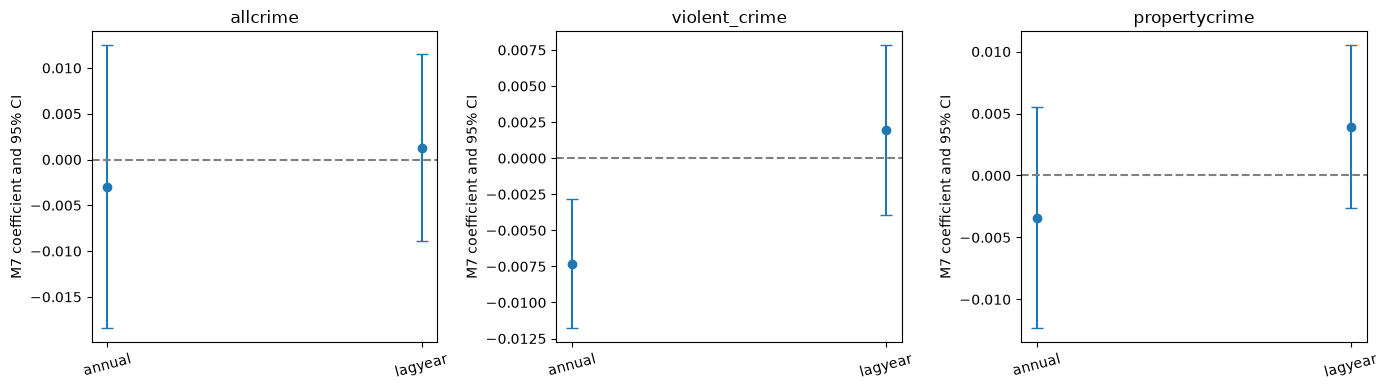

In [12]:
if len(EXPOSURES) > 1:
    fig, axes = plt.subplots(1,3,figsize=(14,4))
    for ax, category in zip(axes, MAIN):
        b = combined.loc[combined.model.eq('M7') & combined.crime.eq(category)].set_index('exposure_label').reindex(EXPOSURES)
        x=np.arange(len(EXPOSURES))
        ax.errorbar(x,b.beta,yerr=np.vstack([b.beta-b.ci_low,b.ci_high-b.beta]),fmt='o',capsize=4)
        ax.axhline(0,color='grey',linestyle='--');ax.set_xticks(x,EXPOSURES,rotation=15)
        ax.set_title(category);ax.set_ylabel('M7 coefficient and 95% CI')
    fig.tight_layout();fig.savefig(OUT / 'm7_timing_comparison.png',dpi=160);plt.show()
else:
    print('This notebook keeps crime timing fixed:', EXPOSURES[0])


## 5. Full M1–M7 sequence on 2012–2013 sales

This narrower common sample removes the 2014 supplied current-year violence zeros. Both exposure timings and all three crime categories are estimated under the same M1–M7 specifications as notebook 01. The previous-year exposure for 2012–2013 sales uses 2011–2012 crime.

In [13]:
sample_2012_2013 = sample.loc[sample.year.between(2012,2013)].copy()
assert set(sample_2012_2013.year.unique()) == {2012,2013}
sample_2012_2013.groupby('year').size().rename('sales').to_csv(OUT / 'sample_2012_2013_by_year.csv')
pre2014_results = []
for EXPOSURE in EXPOSURES:
    panel = 'pre2014_' + EXPOSURE
    results_2012_2013 = estimate_specs(sample_2012_2013, panel, model_specs(False))
    results_2012_2013['exposure_label'] = EXPOSURE
    pre2014_results.append(results_2012_2013)
combined_2012_2013 = pd.concat(pre2014_results, ignore_index=True)
assert combined_2012_2013.N.nunique() == 1
combined_2012_2013.to_csv(OUT / 'combined_2012_2013_models.csv', index=False)
display(combined_2012_2013.loc[combined_2012_2013.model.isin(['M6','M7']),
                               ['exposure_label','model','crime','N','beta','se','p','ci_low','ci_high']]
        .round({'beta':5,'se':5,'p':5,'ci_low':5,'ci_high':5}))

pre2014_annual: 19 regressions on 198,948 identical transactions.


pre2014_lagyear: 19 regressions on 198,948 identical transactions.


,exposure_label,model,crime,N,beta,se,p,ci_low,ci_high
13,annual,M6,allcrime,198948,-0.0093,0.0047,0.0514,-0.0186,6.0000e-05
14,annual,M6,violent_crime,198948,-0.0318,0.0038,0.0000,-0.0392,-2.4280e-02
15,annual,M6,propertycrime,198948,-0.0070,0.0055,0.2007,-0.0177,3.7200e-03
16,annual,M7,allcrime,198948,0.0078,0.0095,0.4106,-0.0108,2.6490e-02
17,annual,M7,violent_crime,198948,-0.0052,0.0040,0.1948,-0.0130,2.6500e-03
18,annual,M7,propertycrime,198948,-0.0015,0.0049,0.7541,-0.0112,8.1200e-03
32,lagyear,M6,allcrime,198948,-0.0087,0.0047,0.0682,-0.0180,6.5000e-04
33,lagyear,M6,violent_crime,198948,-0.0324,0.0041,0.0000,-0.0404,-2.4410e-02
34,lagyear,M6,propertycrime,198948,0.0021,0.0054,0.6974,-0.0084,1.2630e-02
35,lagyear,M7,allcrime,198948,0.0101,0.0066,0.1246,-0.0028,2.3100e-02


## 6. Compare with the full-sample results

The full sample includes sales in 2011 and 2015. This table and figure show how the M6 and M7 coefficients change when those sale years are excluded. Confidence intervals use LSOA-clustered standard errors. The restricted and full estimates are **not** based on identical transactions.

,sample_label,exposure_label,model,crime,N,beta,se,p,ci_low,ci_high,crime_residual_sd,significant_5pct
13,Full: 2011–2015,annual,M6,allcrime,453740,-0.0117,0.0040,0.0034,-0.0196,-0.0039,0.5105,True
14,Full: 2011–2015,annual,M6,violent_crime,453740,-0.0323,0.0028,0.0000,-0.0378,-0.0267,0.5343,True
15,Full: 2011–2015,annual,M6,propertycrime,453740,-0.0053,0.0040,0.1929,-0.0132,0.0027,0.4516,False
16,Full: 2011–2015,annual,M7,allcrime,453740,-0.0033,0.0038,0.3931,-0.0108,0.0042,0.1837,False
17,Full: 2011–2015,annual,M7,violent_crime,453740,-0.0121,0.0019,0.0000,-0.0157,-0.0084,0.4199,True
18,Full: 2011–2015,annual,M7,propertycrime,453740,-0.0018,0.0024,0.4512,-0.0066,0.0029,0.2921,False
32,Full: 2011–2015,lagyear,M6,allcrime,453740,-0.0091,0.0039,0.0186,-0.0168,-0.0015,0.5204,True
33,Full: 2011–2015,lagyear,M6,violent_crime,453740,-0.0249,0.0029,0.0000,-0.0305,-0.0192,0.5875,True
34,Full: 2011–2015,lagyear,M6,propertycrime,453740,-0.0001,0.0036,0.9746,-0.0072,0.0070,0.4656,False
35,Full: 2011–2015,lagyear,M7,allcrime,453740,0.0034,0.0035,0.3265,-0.0034,0.0102,0.2140,False


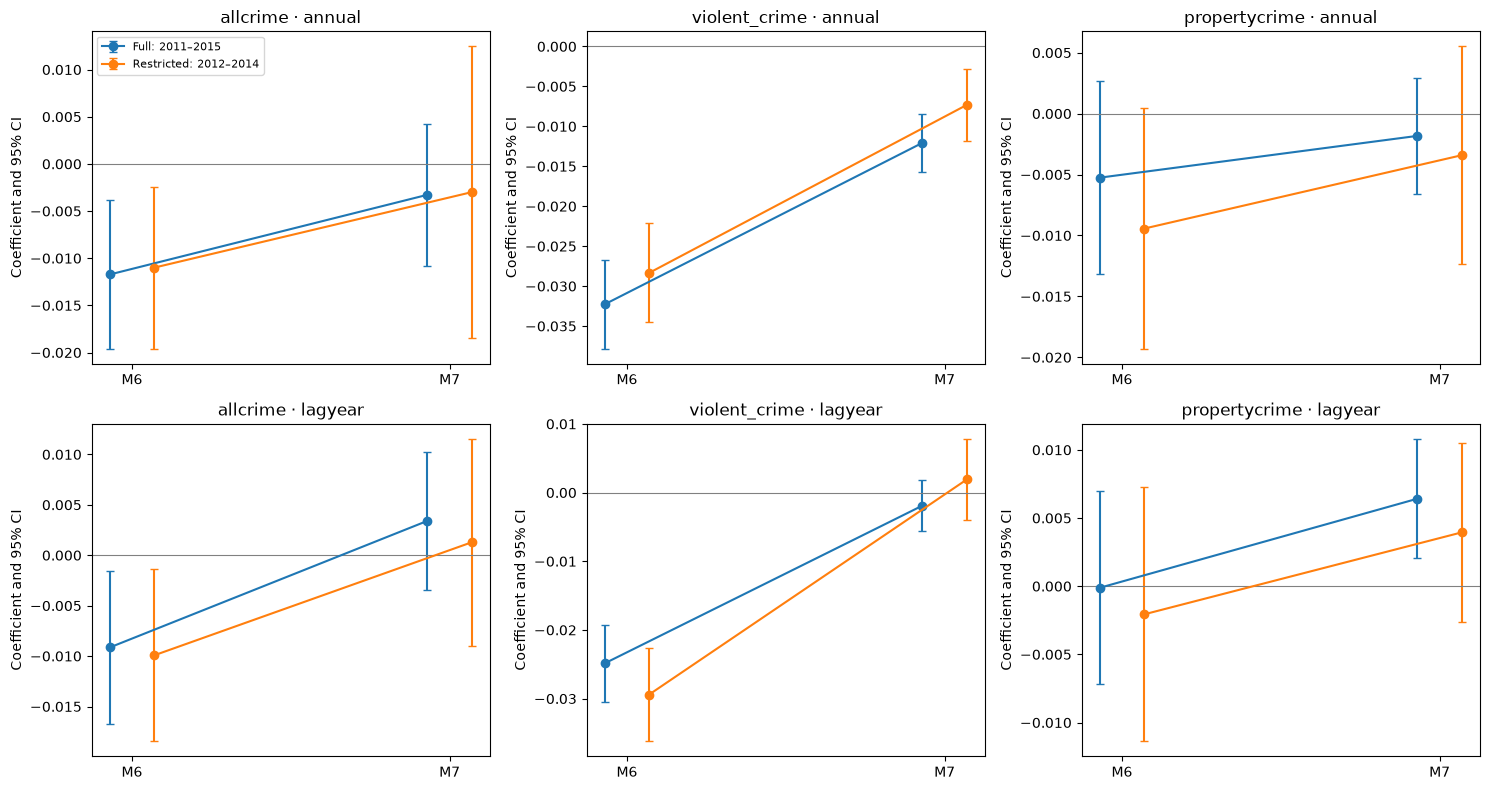

In [14]:
baseline_path = DATA_DIR / '01_crime_original_outputs' / 'combined_primary_models.csv'
if not baseline_path.is_file():
    raise FileNotFoundError('Run 01_crime_original.ipynb first to create the full-sample comparison.')
baseline = pd.read_csv(baseline_path).assign(sample_label='Full: 2011–2015')
restricted = combined.assign(sample_label='Restricted: 2012–2014')
comparison = pd.concat([baseline, restricted], ignore_index=True)
comparison = comparison.loc[comparison.model.isin(['M6','M7']) & comparison.crime.isin(MAIN)].copy()
comparison['significant_5pct'] = comparison.p.lt(.05)
comparison_columns = ['sample_label','exposure_label','model','crime','N','beta','se','p','ci_low','ci_high','crime_residual_sd','significant_5pct']
comparison[comparison_columns].to_csv(OUT / 'full_vs_restricted_m6_m7.csv', index=False)
display(comparison[comparison_columns].round(5))

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=False)
for i, exposure in enumerate(EXPOSURES):
    for j, crime in enumerate(MAIN):
        ax = axes[i,j]
        subset = comparison.loc[comparison.exposure_label.eq(exposure) & comparison.crime.eq(crime)]
        for k, label in enumerate(['Full: 2011–2015','Restricted: 2012–2014']):
            rows = subset.loc[subset.sample_label.eq(label)].set_index('model').reindex(['M6','M7'])
            x = np.arange(2) + (k-.5)*.14
            ax.errorbar(x, rows.beta, yerr=np.vstack([rows.beta-rows.ci_low, rows.ci_high-rows.beta]),
                        fmt='o-', capsize=3, label=label)
        ax.axhline(0, color='0.5', linewidth=.8)
        ax.set_xticks([0,1], ['M6','M7'])
        ax.set_title(f'{crime} · {exposure}')
        ax.set_ylabel('Coefficient and 95% CI')
axes[0,0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / 'full_vs_restricted_m6_m7.png', dpi=160)
plt.show()

## 7. Original/Stata coefficient and significance heatmaps

Each row is a crime category and each column is a model. The three sample windows and two exposure timings share one signed color scale. Each cell prints the coefficient on `ln(1 + crime)` and its two-sided significance: `***` p < .001, `**` p < .01, `*` p < .05, `ns` otherwise. Read the printed estimate as well as the color; large M2 coefficients set the scale. Significance is assessed separately within each cell, and these symbols do not test whether two coefficients differ.

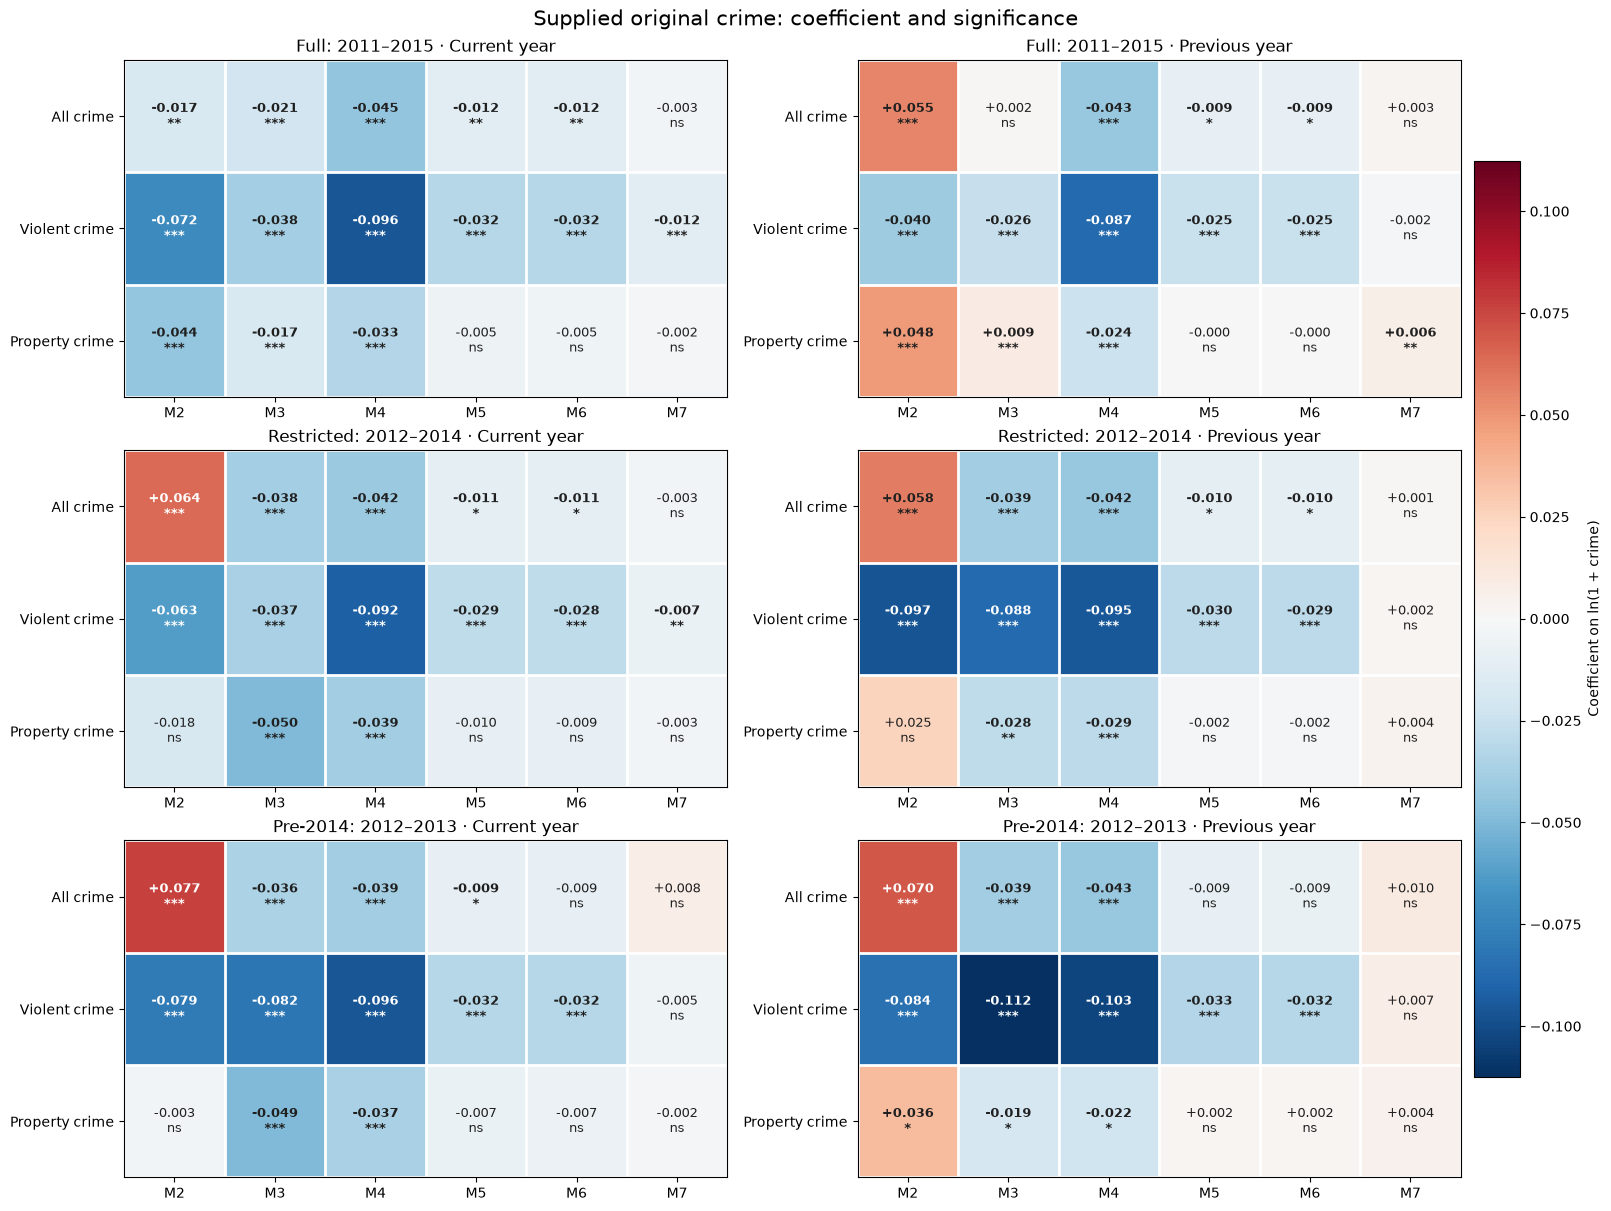

,sample_label,timing,crime,N,beta,se,p,significance
15,Full: 2011–2015,Current year,allcrime,453740,-0.0033,0.0038,0.3931,ns
17,Full: 2011–2015,Current year,propertycrime,453740,-0.0018,0.0024,0.4512,ns
16,Full: 2011–2015,Current year,violent_crime,453740,-0.0121,0.0019,0.0000,***
33,Full: 2011–2015,Previous year,allcrime,453740,0.0034,0.0035,0.3265,ns
35,Full: 2011–2015,Previous year,propertycrime,453740,0.0064,0.0022,0.0041,**
34,Full: 2011–2015,Previous year,violent_crime,453740,-0.0019,0.0019,0.3144,ns
87,Pre-2014: 2012–2013,Current year,allcrime,198948,0.0078,0.0095,0.4106,ns
89,Pre-2014: 2012–2013,Current year,propertycrime,198948,-0.0015,0.0049,0.7541,ns
88,Pre-2014: 2012–2013,Current year,violent_crime,198948,-0.0052,0.0040,0.1948,ns
105,Pre-2014: 2012–2013,Previous year,allcrime,198948,0.0101,0.0066,0.1246,ns


In [15]:
from matplotlib.colors import TwoSlopeNorm

heatmap_rows = []
for label, frame in [('Full: 2011–2015', baseline), ('Restricted: 2012–2014', combined), ('Pre-2014: 2012–2013', combined_2012_2013)]:
    part = frame.loc[frame.model.isin([f'M{i}' for i in range(2,8)])].copy()
    part['sample_label'] = label
    heatmap_rows.append(part)
heatmap_data = pd.concat(heatmap_rows, ignore_index=True)
heatmap_data['timing'] = heatmap_data.crime_exposure.map({'annual':'Current year', 'lagyear':'Previous year'})
heatmap_data['significance'] = np.select(
    [heatmap_data.p.lt(.001), heatmap_data.p.lt(.01), heatmap_data.p.lt(.05)],
    ['***','**','*'], default='ns')
heatmap_columns = ['sample_label','timing','crime','model','N','beta','se','p','ci_low','ci_high','significance']
heatmap_data[heatmap_columns].to_csv(OUT / 'three_samples_m2_m7_significance.csv', index=False, float_format='%.16g')
heatmap_data.loc[heatmap_data.sample_label.ne('Pre-2014: 2012–2013'), heatmap_columns].to_csv(
    OUT / 'full_vs_restricted_m2_m7_significance.csv', index=False, float_format='%.16g')

models = [f'M{i}' for i in range(2,8)]
categories = ['allcrime','violent_crime','propertycrime']
names = ['All crime','Violent crime','Property crime']
timings = ['Current year','Previous year']
samples = ['Full: 2011–2015','Restricted: 2012–2014','Pre-2014: 2012–2013']
limit = float(heatmap_data.beta.abs().max())
norm = TwoSlopeNorm(vmin=-limit,vcenter=0,vmax=limit)
fig, axes = plt.subplots(3,2,figsize=(16,12),constrained_layout=True)
for i, label in enumerate(samples):
    for j, timing in enumerate(timings):
        ax = axes[i,j]
        panel = heatmap_data.loc[heatmap_data.sample_label.eq(label) & heatmap_data.timing.eq(timing)]
        values = panel.pivot(index='crime',columns='model',values='beta').reindex(index=categories,columns=models)
        symbols = panel.pivot(index='crime',columns='model',values='significance').reindex(index=categories,columns=models)
        if values.isna().any().any() or symbols.isna().any().any():
            raise ValueError('Missing original coefficient or significance cell')
        image = ax.imshow(values.to_numpy(),cmap='RdBu_r',norm=norm,aspect='auto')
        ax.set_xticks(range(len(models)),models)
        ax.set_yticks(range(len(categories)),names)
        ax.set_title(f'{label} · {timing}')
        for row in range(len(categories)):
            for col in range(len(models)):
                value, symbol = values.iloc[row,col], symbols.iloc[row,col]
                ink = 'white' if abs(value) > .55*limit else '#202020'
                ax.text(col,row,f'{value:+.3f}\n{symbol}',ha='center',va='center',
                        color=ink,fontsize=9,fontweight='bold' if symbol!='ns' else 'normal')
        ax.set_xticks(np.arange(-.5,len(models),1),minor=True)
        ax.set_yticks(np.arange(-.5,len(categories),1),minor=True)
        ax.grid(which='minor',color='white',linewidth=2)
        ax.tick_params(which='minor',bottom=False,left=False)
fig.suptitle('Supplied original crime: coefficient and significance',fontsize=15)
fig.colorbar(image,ax=axes,shrink=.82,pad=.01,label='Coefficient on ln(1 + crime)')
fig.savefig(OUT / 'original_three_samples_coefficients_significance.png',dpi=180,bbox_inches='tight')
plt.show()

display(heatmap_data.loc[heatmap_data.model.eq('M7'),
                         ['sample_label','timing','crime','N','beta','se','p','significance']]
        .sort_values(['sample_label','timing','crime']).round({'beta':5,'se':5,'p':5}))

**Interpretation:** Treat these coefficients as associations. Compare signs, magnitudes, intervals and stability across samples. The original violent-crime source has a documented 2014–2015 zero-count problem, and original and MPS category definitions differ. The endpoint restriction by itself does not validate the crime measurements.

## 8. What changed in the robustness checks

The 2012–2014 and 2012–2013 common samples contain **316,091** and **198,948** sales, respectively. The full 2011–2015 sample contains 453,740 sales. All three windows use the same model definitions, but changing sale years also changes time coverage and transaction composition.

- **Current-year violence, M7:** β = −0.01206 (p < 0.001) in the full sample; β = −0.00731 (p = 0.00139) on 2012–2014 sales; β = −0.00517 (p = 0.195) on 2012–2013 sales. The last window avoids the anomalous 2014 current-year violence zeros.
- **Previous-year property crime, M7:** β = +0.00642 (p = 0.00410) in the full sample; β = +0.00395 (p = 0.236) on 2012–2014 sales; β = +0.00441 (p = 0.310) on 2012–2013 sales.
- **All six M7 crime/timing estimates are insignificant at 5% in the 2012–2013 sample.** The M6 violence coefficients remain negative and significant in that sample, so the M6-to-M7 pattern persists even before the 2014 zero-count year.

These results weaken the case for treating the two significant original-data full-sample M7 coefficients as robust. They do not isolate why the estimates change; shorter coverage, fewer sales and measurement differences all matter. Verified violent-crime data remain necessary to resolve the original-source anomaly.